In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

plt.style.use("ggplot")

In [2]:
df = pd.read_csv("../data/processed_data.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Units,Gross Profit,Cost,Year,Month,Month Name,Day,Day of Week,Profit Margin (%),Selling Price per Unit
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,...,2,4.22,2.28,2024,1,January,3,Wednesday,64.923077,3.25
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,2,4.90,2.60,2024,1,January,4,Thursday,65.333333,3.75
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.47,3.00,2024,1,January,4,Thursday,71.346705,3.49
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.50,3.30,2024,1,January,4,Thursday,69.444444,3.60
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,3,7.35,3.90,2024,1,January,5,Friday,65.333333,3.75


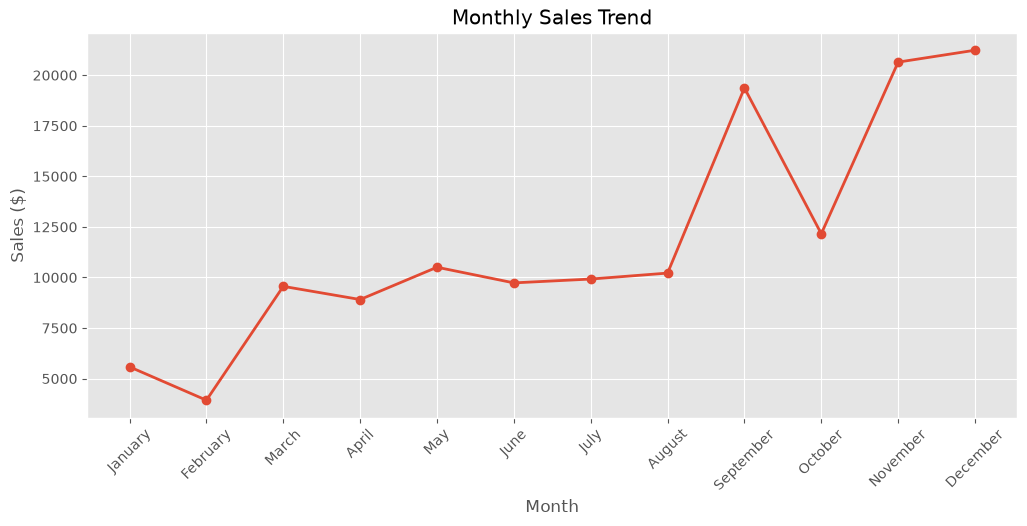

In [3]:
# Ensure months appear in calendar order
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_sales = (
    df.groupby("Month Name")["Sales"]
      .sum()
      .reindex(month_order)
)

plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", linewidth=2)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

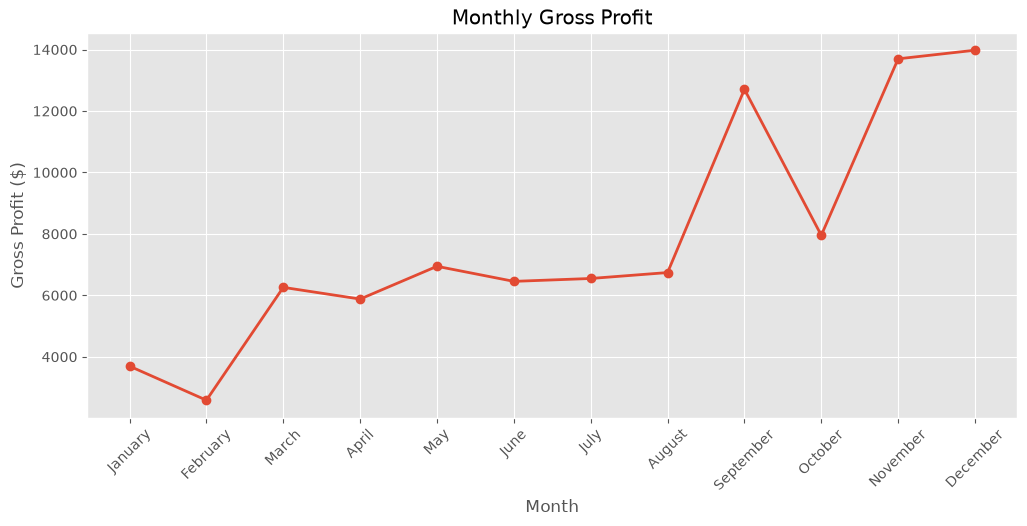

In [4]:
monthly_profit = (
    df.groupby("Month Name")["Gross Profit"]
      .sum()
      .reindex(month_order)
)

plt.figure(figsize=(12,5))
plt.plot(monthly_profit.index, monthly_profit.values, marker="o", linewidth=2)

plt.title("Monthly Gross Profit")
plt.xlabel("Month")
plt.ylabel("Gross Profit ($)")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

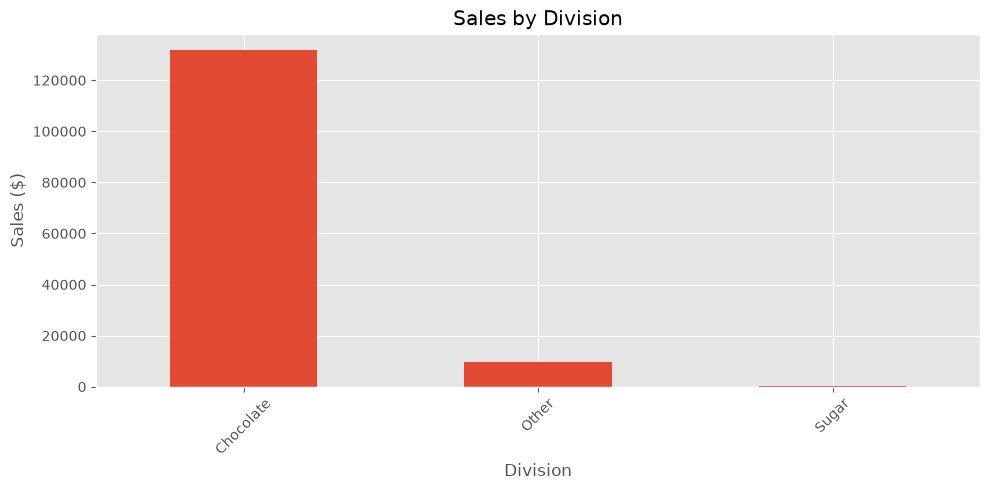

In [5]:
division_sales = (
    df.groupby("Division")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))
division_sales.plot(kind="bar")

plt.title("Sales by Division")
plt.xlabel("Division")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

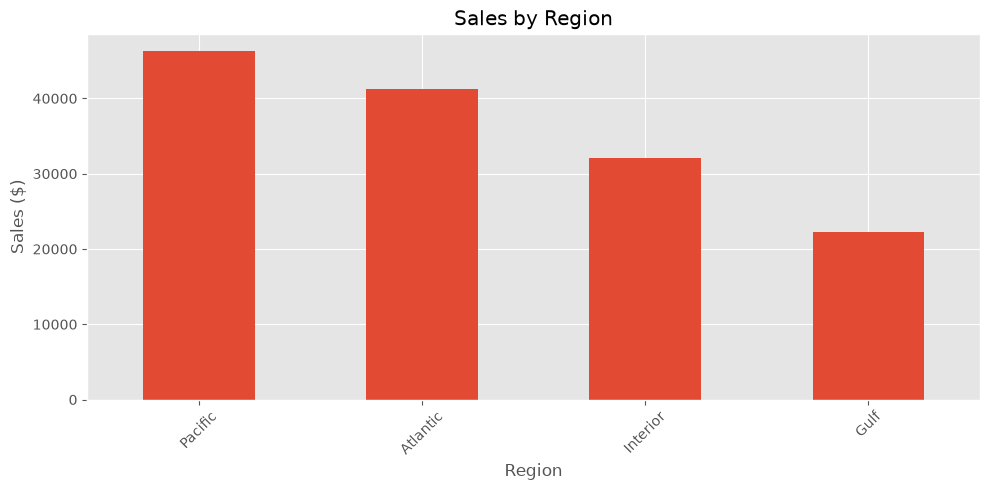

In [6]:
region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))
region_sales.plot(kind="bar")

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [7]:
df["Year-Month"] = df["Order Date"].dt.to_period("M")

AttributeError: Can only use .dt accessor with datetimelike values

In [8]:
print(df["Order Date"].dtype)


str


In [9]:
import pandas as pd

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

ValueError: time data "2024-01-03" doesn't match format "%d-%m-%Y". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [10]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [11]:
df["Year-Month"] = df["Order Date"].dt.to_period("M")

In [12]:
print(df["Order Date"].head())
print(df["Order Date"].dtype)

0   2024-01-03
1   2024-01-04
2   2024-01-04
3   2024-01-04
4   2024-01-05
Name: Order Date, dtype: datetime64[us]
datetime64[us]


In [13]:
df["Year-Month"] = df["Order Date"].dt.to_period("M")

In [14]:
monthly_profit = df.groupby("Year-Month")["Gross Profit"].sum()

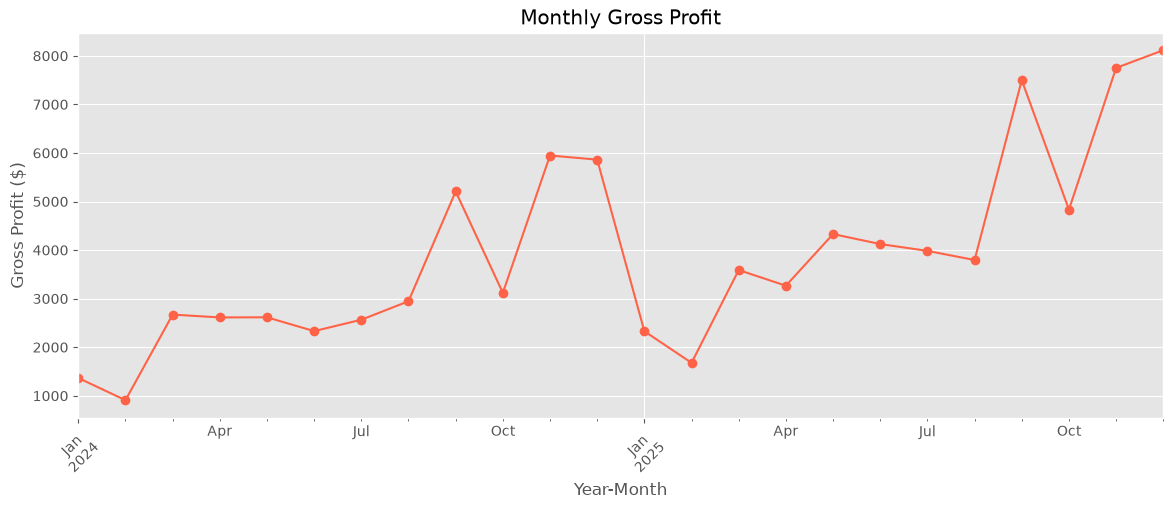

In [15]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")

plt.figure(figsize=(14,5))

monthly_profit.plot(marker="o", color="tomato")

plt.title("Monthly Gross Profit")
plt.xlabel("Year-Month")
plt.ylabel("Gross Profit ($)")
plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [16]:
# Check if there are duplicate Order IDs
print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())

# Show the first and last 5 rows
display(df[["Order ID", "Order Date", "Ship Date"]].head())
display(df[["Order ID", "Order Date", "Ship Date"]].tail())

Duplicate Order IDs: 1645


,Order ID,Order Date,Ship Date
0,US-2021-103800-CHO-MIL-31000,2024-01-03,30-06-2026
1,US-2021-112326-CHO-TRI-54000,2024-01-04,01-07-2026
2,US-2021-112326-CHO-NUT-13000,2024-01-04,01-07-2026
3,US-2021-112326-CHO-SCR-58000,2024-01-04,01-07-2026
4,US-2021-141817-CHO-TRI-54000,2024-01-05,05-07-2026


,Order ID,Order Date,Ship Date
10189,US-2024-143259-CHO-MIL-31000,2025-12-30,26-06-2030
10190,US-2024-115427-CHO-NUT-13000,2025-12-30,26-06-2030
10191,US-2024-156720-CHO-SCR-58000,2025-12-30,26-06-2030
10192,US-2024-143259-CHO-TRI-54000,2025-12-30,26-06-2030
10193,CA-2024-143500-CHO-SCR-58000,2025-12-30,26-06-2030
